# Outbreak detection walkthrough

This notebook goes from raw multi-source signals to an explained alert, using the `sentinel_ml` library and synthetic data:

1. Generate surveillance data
2. Engineer features
3. Detect anomalies (ensemble vs. EARS C2)
4. Score outbreak likelihood (High/Medium/Low) and explain the score
5. Forecast 7/14/30 days with intervals
6. Find spatial hotspots

Setup: `pip install -e 'ml[plots]'` from the repo root.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sentinel_ml.data import SyntheticConfig, generate_surveillance, REGIONS
from sentinel_ml.features import build_features, add_outbreak_target

panel = generate_surveillance(SyntheticConfig(regions=REGIONS[:10], diseases=['INFLUENZA', 'CLI', 'MEASLES']))
feats = add_outbreak_target(build_features(panel))
feats = feats[feats.date >= feats.date.min() + pd.Timedelta(days=42)]
panel.head()

,date,region_id,region_name,state,lat,lon,population,disease,cases,ed_visits,admissions,deaths,positivity,otc_sales,wastewater,outbreak
0,2023-01-01,04013,Phoenix,AZ,33.45,-112.07,1600000,CLI,85,130,8,0,0.0421,106.47,92.30,0
1,2023-01-02,04013,Phoenix,AZ,33.45,-112.07,1600000,CLI,115,600,4,0,0.0422,106.22,78.72,0
2,2023-01-03,04013,Phoenix,AZ,33.45,-112.07,1600000,CLI,112,305,2,0,0.0431,106.03,72.66,0
3,2023-01-04,04013,Phoenix,AZ,33.45,-112.07,1600000,CLI,55,326,2,0,0.0434,116.90,86.34,0
4,2023-01-05,04013,Phoenix,AZ,33.45,-112.07,1600000,CLI,65,181,2,0,0.0467,105.99,63.75,0


## Leading indicators
In this data, wastewater and ED visits rise **before** confirmed cases. That timing is the basis for early detection.

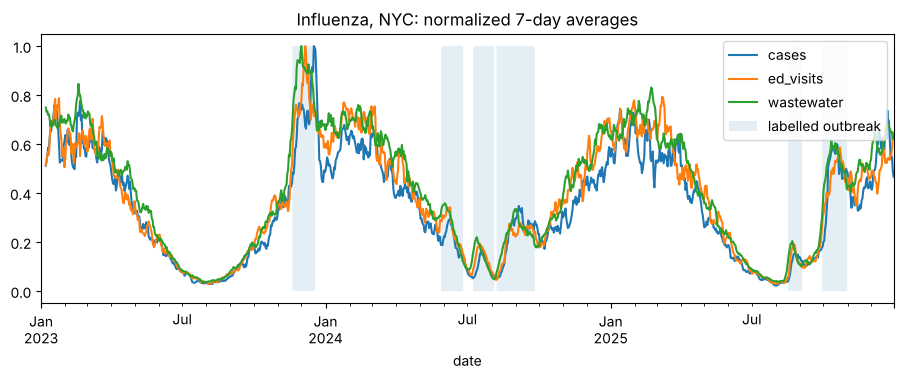

In [2]:
s = panel[(panel.disease == 'INFLUENZA') & (panel.region_id == REGIONS[0].region_id)].set_index('date')
ax = (s[['cases', 'ed_visits', 'wastewater']].rolling(7).mean() / s[['cases', 'ed_visits', 'wastewater']].rolling(7).mean().max()).plot(figsize=(11, 3.5))
ax.fill_between(s.index, 0, s.outbreak, alpha=0.12, step='mid', label='labelled outbreak')
ax.set_title('Influenza, NYC: normalized 7-day averages'); ax.legend();

## Anomaly detection: ensemble vs. EARS C2

In [3]:
from sentinel_ml.anomaly import EnsembleAnomalyDetector
from sklearn.metrics import roc_auc_score
train, test = feats[feats.date < '2025-01-01'], feats[feats.date >= '2025-01-01']
ens = EnsembleAnomalyDetector(contamination=0.03).fit(train)
print('Ensemble AUC', round(roc_auc_score(test.outbreak, ens.score(test)), 3))
print('EARS C2 AUC ', round(roc_auc_score(test.outbreak, test.cases_zscore.fillna(0)), 3))

/tmp/claude-0/venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Ensemble AUC 0.895
EARS C2 AUC  0.747


## Outbreak likelihood classifier with TreeSHAP explanations

In [4]:
from sentinel_ml.classification import OutbreakClassifier, classification_metrics
clf = OutbreakClassifier().fit(train)
p = clf.predict_proba(test)
m = classification_metrics(test.target_outbreak, p, clf.decision_threshold)
{k: round(m[k], 3) for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}

{'accuracy': 0.973,
 'precision': 0.824,
 'recall': 0.782,
 'f1': 0.803,
 'roc_auc': 0.968}

In [5]:
top = test.assign(p=p).sort_values('p', ascending=False).head(3)
for (_, row), expl in zip(top.iterrows(), clf.explain(top)):
    print(row.date.date(), row.disease, row.region_name, f'p={row.p:.2f}', expl)

2025-07-07 CLI New York City p=1.00 [('otc_ratio_7_28', 8.5063), ('wastewater_growth_7', 2.2601), ('doy_cos', 1.6788), ('wastewater_ratio_7_28', 0.7011)]
2025-03-04 CLI Phoenix p=1.00 [('otc_ratio_7_28', 7.0422), ('incidence_7d_per_100k', 2.5589), ('doy_sin', -1.5032), ('wastewater_growth_7', 1.2653)]
2025-03-05 CLI Phoenix p=1.00 [('otc_ratio_7_28', 7.088), ('doy_sin', -2.572), ('incidence_7d_per_100k', 2.4157), ('ed_ratio_7_28', 1.0988)]


## Forecasting with conformal intervals

{'horizon_days': 14,
 'forecast_cases': 806.1,
 'forecast_cases_lower': 654.4,
 'forecast_cases_upper': 1000.8,
 'expected_admissions': 17.1,
 'expected_deaths': 1.06,
 'admissions_per_100k': 0.21,
 'deaths_per_100k': 0.013,
 'hospitalization_risk': 'low',
 'mortality_risk': 'low',
 'trend': 'decreasing'}

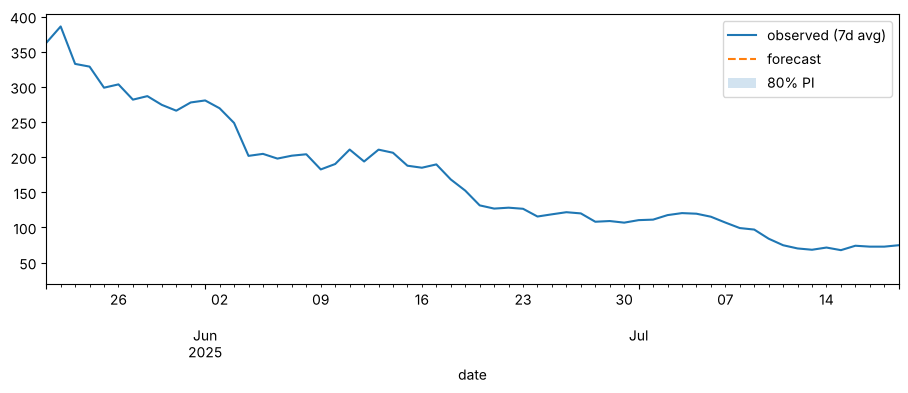

In [6]:
from sentinel_ml.forecasting import SeasonalNaiveForecaster, XGBoostForecaster, derive_risk
xgbf = XGBoostForecaster(stride=7).fit(train)
hist = test[(test.disease == 'INFLUENZA') & (test.region_id == REGIONS[0].region_id)].iloc[:200]
fc = xgbf.predict(hist, 30)
ax = hist.set_index('date').cases.rolling(7).mean().tail(60).plot(figsize=(11, 3.5), label='observed (7d avg)')
ax.plot(fc.dates, fc.mean, '--', label='forecast'); ax.fill_between(fc.dates, fc.lower, fc.upper, alpha=0.2, label='80% PI'); ax.legend()
derive_risk(fc, hist, 'INFLUENZA', REGIONS[0].population, 14).as_dict()

## Spatial hotspots (HDBSCAN)

In [7]:
from sentinel_ml.data.synthetic import generate_case_line_list
from sentinel_ml.spatial import detect_hotspots
line = generate_case_line_list(panel[panel.date > panel.date.max() - pd.Timedelta(days=104)], max_rows=20000)
flu = line[line.disease == 'INFLUENZA']
cut = flu.date.max() - pd.Timedelta(days=21)
[h.as_dict() for h in detect_hotspots(flu[flu.date > cut], flu[flu.date <= cut], window_ratio=83/21)][:5]

[{'cluster_id': 4,
  'disease': 'INFLUENZA',
  'case_count': 187,
  'centroid_lat': 29.4435,
  'centroid_lon': -98.5384,
  'radius_km': 48.57,
  'relative_risk': 2.19,
  'method': 'hdbscan'},
 {'cluster_id': 0,
  'disease': 'INFLUENZA',
  'case_count': 70,
  'centroid_lat': 25.8355,
  'centroid_lon': -80.2481,
  'radius_km': 69.74,
  'relative_risk': 2.05,
  'method': 'hdbscan'},
 {'cluster_id': 6,
  'disease': 'INFLUENZA',
  'case_count': 169,
  'centroid_lat': 32.6922,
  'centroid_lon': -117.1337,
  'radius_km': 49.44,
  'relative_risk': 2.02,
  'method': 'hdbscan'},
 {'cluster_id': 1,
  'disease': 'INFLUENZA',
  'case_count': 194,
  'centroid_lat': 33.3975,
  'centroid_lon': -112.0612,
  'radius_km': 56.15,
  'relative_risk': 1.76,
  'method': 'hdbscan'},
 {'cluster_id': 8,
  'disease': 'INFLUENZA',
  'case_count': 164,
  'centroid_lat': 39.966,
  'centroid_lon': -75.1152,
  'radius_km': 44.81,
  'relative_risk': 1.73,
  'method': 'hdbscan'}]